# cfDNA LEAF-1 versus 100 kbp coordinate binning AUC(Figure 6e)

Cancer-vs-healthy AUC-ROC (95% bootstrap CI) for the LEAF-1 embedding classifier and a 100 kbp coordinate-binning baseline on the internal cfDNA cohort.

Reads `../data/cfdna_leaf1_vs_binning_predictions.csv` and writes the figure to `../output/`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)

DATA: /home/jingz/leaf-1-figures/cfdna/data
OUT : /home/jingz/leaf-1-figures/cfdna/output


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score


def auc_with_ci(y_true, y_prob, n_bootstraps=1000, seed=42):
    """AUC and 95% CI via stratified (per-class) bootstrap."""
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    obs = roc_auc_score(y_true, y_prob)
    rng = np.random.RandomState(seed)
    pos_idx = np.where(y_true == 1)[0]
    neg_idx = np.where(y_true == 0)[0]
    boot = []
    for _ in range(n_bootstraps):
        p = rng.choice(pos_idx, len(pos_idx), replace=True)
        n = rng.choice(neg_idx, len(neg_idx), replace=True)
        yt = np.concatenate([y_true[p], y_true[n]])
        yp = np.concatenate([y_prob[p], y_prob[n]])
        boot.append(roc_auc_score(yt, yp))
    return obs, float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


df = pd.read_csv(DATA / "cfdna_leaf1_vs_binning_predictions.csv")
y_true = (df["group"].str.lower() != "healthy").astype(int).values

# (column, display label, colour) for the two methods compared.
# The `binning_30k` column is 30,000 genome-wide coordinate bins, i.e. ~100 kbp
# per bin (~3.1 Gbp / 30k); labelled by bin width to match the manuscript.
METHODS = [
    ("leaf1", "LEAF-1", OKABE_ITO["blue"]),
    ("binning_30k", "Binning (100 kbp)", OKABE_ITO["orange"]),
]

rows = []
for col, label, _ in METHODS:
    auc, lo, hi = auc_with_ci(y_true, df[col].values)
    rows.append({"method": col, "label": label, "auc": auc, "ci_low": lo, "ci_high": hi})
    print(f"{label}: AUC={auc:.3f} (95% CI [{lo:.3f}, {hi:.3f}])")
res = pd.DataFrame(rows)
res["n_pos"] = int(y_true.sum())
res["n_neg"] = int((y_true == 0).sum())

LEAF-1: AUC=0.833 (95% CI [0.556, 1.000])
Binning (100 kbp): AUC=0.639 (95% CI [0.306, 0.889])


saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_leaf1_vs_binning_auc.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_leaf1_vs_binning_auc.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_leaf1_vs_binning_auc.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_leaf1_vs_binning_auc.tsv


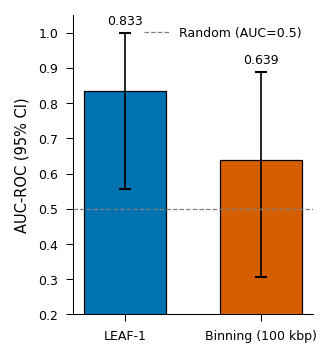

In [3]:
labels = res["label"].tolist()
aucs = res["auc"].values
lower_err = res["auc"].values - res["ci_low"].values
upper_err = res["ci_high"].values - res["auc"].values
colors = [c for _, _, c in METHODS]

fig, ax = plt.subplots(figsize=(2.2, 2.4))
x = np.arange(len(labels))
bars = ax.bar(
    x, aucs,
    yerr=[lower_err, upper_err],
    capsize=3,
    color=colors,
    edgecolor="black",
    linewidth=0.6,
    width=0.6,
    error_kw=dict(elinewidth=0.8, ecolor="black"),
)
for bar, auc, hi in zip(bars, aucs, res["ci_high"].values):
    ax.text(bar.get_x() + bar.get_width() / 2, hi + 0.015, f"{auc:.3f}",
            ha="center", va="bottom", fontsize=6)

ax.axhline(0.5, color="0.5", linestyle="--", lw=0.6, label="Random (AUC=0.5)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0.2, 1.05)
ax.set_ylabel("AUC-ROC (95% CI)")
ax.legend(loc="upper right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, OUT, "cfdna_leaf1_vs_binning_auc", data=res)